# Kenya Land Readiness Atlas — Satellite Modeling
## CRISP-DM Analysis · Target: LORO Macro-F1 ≥ 0.60

**Author:** Valerie Jerono — Reg. No. 222331  
**Programme:** MSc Data Science & Analytics, Strathmore University  
**Dataset:** Sentinel-2 SR (10 bands) · WorldCover v200 labels · 13 counties · 5 climate zones  
**Current baseline:** Block CV F1 = 0.58 | LORO mean F1 = 0.42 | LORO arid = 0.26  

---

### What this notebook does (CRISP-DM structure)

| Phase | Section | Content |
|---|---|---|
| Business Understanding | §0 | Setup, config, success criteria |
| Data Understanding | §1–§2 | EDA: class distribution, spectral signatures, zone imbalance |
| Data Preparation | §3 | Pull / load data, build spatial splits |
| Modelling L0 | §4 | Decision Tree + LightGBM baseline (tabular, no GPU) |
| Modelling L1 | §5 | Zone-stratified LightGBM + LOZO evaluation |
| Modelling L2 | §6 | EfficientNet-B0 + SpectralChannelAttention CNN |
| Modelling L3 | §7 | Temperature scaling calibration |
| Evaluation | §8 | Consolidated LORO/LOZO comparison table + confusion matrices |
| Deployment | §9 | ONNX export + atlas CSV for MILP integration |

---
## §0 · Business Understanding — Setup & Config

In [35]:
# ── Install dependencies (Colab-safe) ─────────────────────────────────────────
import subprocess, sys

def pip_install(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + list(pkgs))

pip_install("earthengine-api", "lightgbm", "scikit-learn", "matplotlib",
            "seaborn", "pandas", "numpy", "torch", "torchvision",
            "mlflow", "pyyaml", "onnx", "onnxruntime")
print("All dependencies installed.")

All dependencies installed.


In [36]:
# ── Mount Drive & clone repo (Colab) ──────────────────────────────────────────
import os
import sys
import subprocess
from pathlib import Path

IN_COLAB = 'google.colab' in str(sys.modules)
REPO_ROOT = None

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive/land_atlas_baseline")
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)

    REPO_ROOT = Path("/content/Satellite")

    if not REPO_ROOT.exists():
        subprocess.check_call([
            "git", "clone",
            "https://github.com/VAL-Jerono/Satellite.git",
            str(REPO_ROOT)
        ])
    else:
        # Pull latest changes if repo directory already exists
        subprocess.run(["git", "-C", str(REPO_ROOT), "pull"], check=False)

    os.chdir(REPO_ROOT)
else:
    # Running locally — locate root containing configs/config.yaml
    REPO_ROOT = Path(".").resolve()
    while not (REPO_ROOT / "configs" / "config.yaml").exists():
        REPO_ROOT = REPO_ROOT.parent
        if REPO_ROOT == REPO_ROOT.parent:
            raise RuntimeError("Cannot find Satellite repo root. Run from inside the Satellite directory.")
    os.chdir(REPO_ROOT)

sys.path.insert(0, str(REPO_ROOT))
print(f"Working from: {Path.cwd()}")
print(f"Repo root:    {REPO_ROOT}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working from: /content/Satellite
Repo root:    /content/Satellite


In [37]:
# ── Global config & constants ─────────────────────────────────────────────────
import yaml
import numpy as np
import pandas as pd

CFG  = yaml.safe_load((REPO_ROOT / "configs" / "config.yaml").read_text())
RGN  = yaml.safe_load((REPO_ROOT / "configs" / "regions.yaml").read_text())

CLASSES      = RGN["classes"]                          # 6 land-cover classes
K            = len(CLASSES)
SEED         = CFG["training"]["seed"]
BLOCK_DEG    = CFG["training"]["block_deg"]
N_FOLDS      = CFG["training"]["n_folds"]
PATCH_SIZE   = CFG["training"]["patch_size"]

CLIMATE_ZONE = {k: v.get("climate_zone", "unknown") for k, v in RGN["regions"].items()}
ALL_REGIONS  = list(RGN["regions"].keys())
ALL_ZONES    = sorted(set(CLIMATE_ZONE.values()))

# Feature columns used in tabular modelling
BANDS  = ["B2","B3","B4","B5","B6","B7","B8","B8A","B11","B12"]
IDX    = ["NDVI","NDWI","MNDWI","NDBI"]
EXTRA  = ["NDVI_p10","NDVI_p90","NDVI_stdDev",
          "ndvi_wet","ndvi_dry","ndvi_seasonal_swing",
          "elev","slope","twi"]
# ALL_FEATURES: full candidate list — filtered to CSV columns after load
ALL_FEATURES = BANDS + IDX + EXTRA  # 23 total
FEATURES     = ALL_FEATURES          # placeholder; refined in §1.1 after CSV load

# ── Success Criteria (reference card) ─────────────────────────────────────────
TARGETS = {
    "block_cv_macro_f1" : 0.75,
    "loro_mean_macro_f1": 0.60,
    "loro_arid_macro_f1": 0.50,
    "ece"               : 0.08,
}

print("Success criteria:")
for k, v in TARGETS.items():
    print(f"  {k:<30} ≥ {v}" if "f1" in k else f"  {k:<30} ≤ {v}")
print(f"\nClasses ({K}): {CLASSES}")
print(f"Regions ({len(ALL_REGIONS)}): {ALL_REGIONS}")
print(f"Climate zones ({len(ALL_ZONES)}): {ALL_ZONES}")

Success criteria:
  block_cv_macro_f1              ≥ 0.75
  loro_mean_macro_f1             ≥ 0.6
  loro_arid_macro_f1             ≥ 0.5
  ece                            ≤ 0.08

Classes (6): ['built_up', 'cropland', 'trees', 'grass_shrub', 'water', 'bare']
Regions (13): ['highland', 'muranga', 'nyandarua', 'coast', 'kwale', 'lamu', 'arid', 'turkana', 'wajir', 'lake_basin', 'siaya', 'nakuru', 'kajiado']
Climate zones (5): ['asal_zone', 'coastal_zone', 'highland_zone', 'lake_zone', 'rift_zone']


---
## §1 · Data Understanding — Pull or Load the Feature CSV

The feature CSV is produced by `data/pipeline/ee_pull.py` → `data/npy_to_csv.py`.
If it does not exist locally, we pull it from Drive (Colab) or run EE pull directly.

> **No GPU needed for §1–§5.** The EfficientNet CNN in §6 requires a GPU.
>
> If EE data is not available, §4 and §5 still run using the synthetic
> demo dataset generated in §1.2. Switch `USE_EE = True` when real data is ready.

In [38]:
# ── §1.1  Load feature CSV ────────────────────────────────────────────────────
# Priority: (1) local raw CSV, (2) Drive, (3) run EE pull, (4) synthetic demo

USE_EE = False   # Set True if you have GEE credentials and want to pull fresh data
GCP_PROJECT = "your-gcp-project-id"   # set this if USE_EE = True

RAW_CSV = REPO_ROOT / CFG["paths"]["raw_csv"]

SEARCH_PATHS = [
    RAW_CSV,
    Path("/content/drive/MyDrive/land_atlas_baseline") / RAW_CSV.name,
    Path("/content/land_atlas_baseline") / RAW_CSV.name,
]

df = None
for p in SEARCH_PATHS:
    if p.exists() and p.stat().st_size > 0:
        df = pd.read_csv(p)
        print(f"Loaded CSV from: {p}  shape={df.shape}")
        break

if df is None and USE_EE:
    print("No cached CSV found. Pulling from Earth Engine...")
    from data.pipeline.ee_pull import pull
    df = pull(project=GCP_PROJECT)
    RAW_CSV.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(RAW_CSV, index=False)
    print(f"Saved to {RAW_CSV}")

if df is None:
    print("⚠  No real data found. Generating synthetic demo dataset for code validation.")
    print("   Set USE_EE=True and GCP_PROJECT to pull real Sentinel-2 data.")
    np.random.seed(SEED)
    n_per = 400
    parts = []
    for reg, meta in RGN["regions"].items():
        zone = meta.get("climate_zone", "unknown")
        bbox = meta["bbox"]
        for cls_idx in range(K):
            n = n_per if reg not in ["arid", "wajir"] else max(22, n_per // 3)
            row_data = {}
            for b in BANDS:
                base = 0.08 + cls_idx * 0.03 + np.random.randn() * 0.01
                row_data[b] = np.clip(np.random.normal(base, 0.05, n), 0, 1)
            ndvi_base = [0.1, 0.5, 0.7, 0.4, -0.1, 0.05][cls_idx]
            row_data["NDVI"]  = np.clip(np.random.normal(ndvi_base, 0.08, n), -1, 1)
            row_data["NDWI"]  = np.clip(np.random.normal(-0.2 + cls_idx * 0.02, 0.1, n), -1, 1)
            row_data["MNDWI"] = np.clip(np.random.normal(-0.1, 0.1, n), -1, 1)
            row_data["NDBI"]  = np.clip(np.random.normal(0.1 - cls_idx * 0.02, 0.08, n), -1, 1)
            row_data["NDVI_p10"] = row_data["NDVI"] - 0.1
            row_data["NDVI_p90"] = row_data["NDVI"] + 0.1
            row_data["NDVI_stdDev"] = np.abs(np.random.normal(0.05, 0.02, n))
            swing = 0.4 if cls_idx == 1 else 0.05
            row_data["ndvi_wet"]  = row_data["NDVI"] + swing / 2
            row_data["ndvi_dry"]  = row_data["NDVI"] - swing / 2
            row_data["ndvi_seasonal_swing"] = np.full(n, swing) + np.random.randn(n) * 0.02
            row_data["elev"]  = np.random.normal(1200 if "highland" in zone else 500, 100, n)
            row_data["slope"] = np.abs(np.random.normal(5, 3, n))
            row_data["twi"]   = np.random.normal(8, 2, n)
            row_data["label"]  = cls_idx
            row_data["region"] = reg
            row_data["climate_zone"] = zone
            row_data["lon"] = np.random.uniform(bbox[0], bbox[2], n)
            row_data["lat"] = np.random.uniform(bbox[1], bbox[3], n)
            row_data["weight"] = 1.0 / n
            parts.append(pd.DataFrame(row_data))
    df = pd.concat(parts, ignore_index=True)
    print(f"Synthetic dataset: {df.shape}")

# ── Post-load column normalisation ──────────────────────────────────────
# Filter FEATURES to only columns that exist in this CSV.
# Older Drive CSVs (produced before seasonal/TWI features were added to
# ee_pull.py) may be missing ndvi_wet, ndvi_dry, ndvi_seasonal_swing, twi.
# Filtering here matches land_atlas_baseline.ipynb behavior exactly.
FEATURES = [c for c in ALL_FEATURES if c in df.columns]
missing  = [c for c in ALL_FEATURES if c not in df.columns]
if missing:
    print(f"⚠  {len(missing)} feature(s) not in CSV — excluded: {missing}")
    print("   Re-run land_atlas_baseline.ipynb to regenerate samples_*.csv with all features.")
print(f"Using {len(FEATURES)} features: {FEATURES}")

# Ensure climate_zone column exists
if "climate_zone" not in df.columns:
    df["climate_zone"] = df["region"].map(CLIMATE_ZONE).fillna("unknown")

# Ensure weight column exists (older CSVs may not have it)
if "weight" not in df.columns:
    df["weight"] = 1.0

df["label"] = df["label"].astype(int)
df = df.dropna(subset=FEATURES + ["label"]).reset_index(drop=True)

print(f"\nFinal dataset: {df.shape}")
print(f"Regions: {sorted(df['region'].unique())}")
print(f"Climate zones: {sorted(df['climate_zone'].unique())}")

Loaded CSV from: /content/drive/MyDrive/land_atlas_baseline/samples_2021_n400.csv  shape=(28121, 25)
⚠  4 feature(s) not in CSV — excluded: ['ndvi_wet', 'ndvi_dry', 'ndvi_seasonal_swing', 'twi']
   Re-run land_atlas_baseline.ipynb to regenerate samples_*.csv with all features.
Using 19 features: ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NDVI_p10', 'NDVI_p90', 'NDVI_stdDev', 'elev', 'slope']

Final dataset: (28121, 26)
Regions: ['arid', 'coast', 'highland', 'kajiado', 'kwale', 'lake_basin', 'lamu', 'muranga', 'nakuru', 'nyandarua', 'siaya', 'turkana', 'wajir']
Climate zones: ['asal_zone', 'coastal_zone', 'highland_zone', 'lake_zone', 'rift_zone']


---
## §2 · Data Understanding — EDA

Four EDA passes:
1. Class distribution by region and zone
2. ASAL class deficit audit
3. Spectral signature curves (mean band reflectance per class)
4. Seasonal NDVI swing — the key cropland discriminant

Sample counts per region × class:


label,bare,built_up,cropland,grass_shrub,trees,water
region,,,,,,
arid,400,210,83,400,359,22
coast,400,400,400,400,400,351
highland,347,331,378,400,400,400
kajiado,400,400,400,400,400,400
kwale,400,400,400,400,400,372
lake_basin,375,375,375,375,375,400
lamu,325,350,350,350,270,400
muranga,400,400,400,400,400,388
nakuru,389,400,400,400,400,400


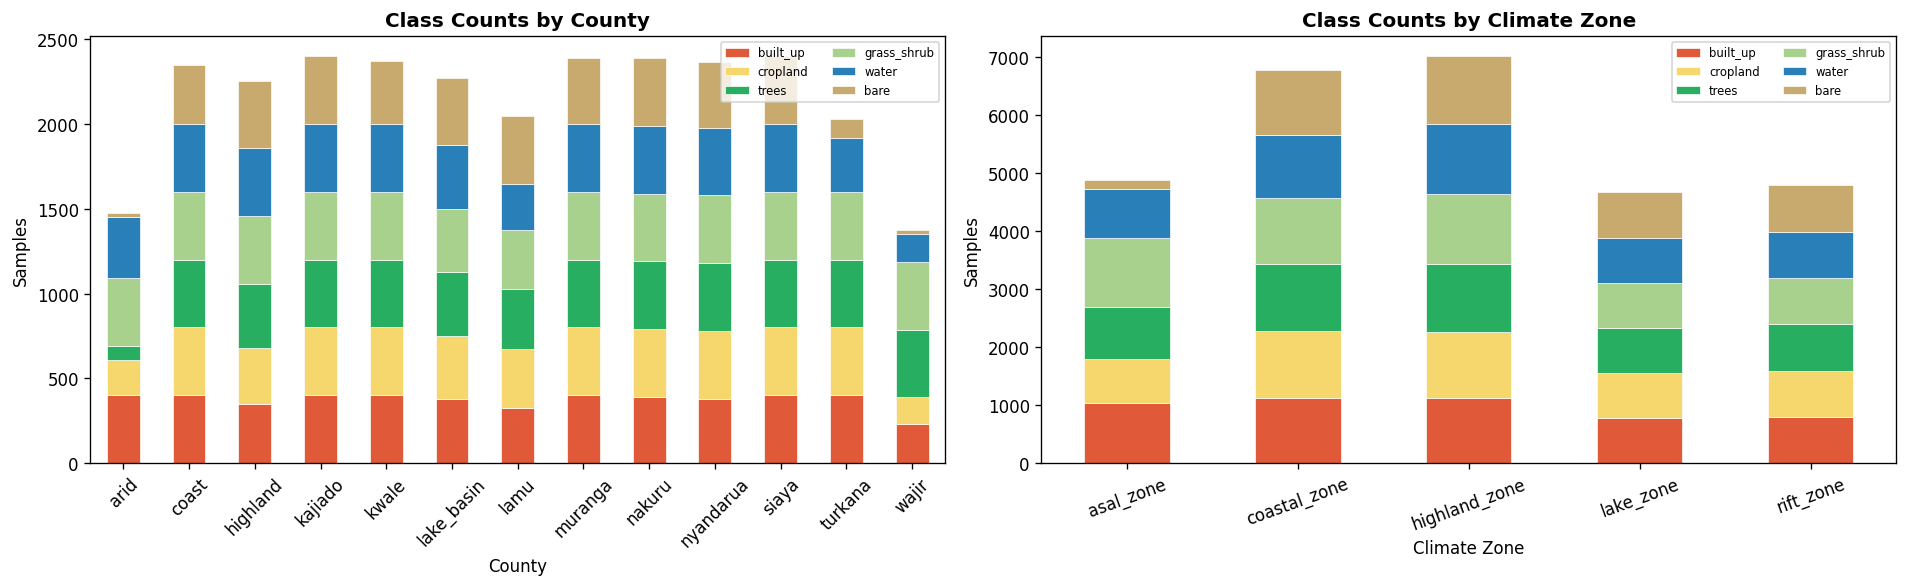


⚠  ASAL zone class counts (highlight deficits):


label,bare,built_up,cropland,grass_shrub,trees,water
region,,,,,,
arid,400,210,83,400,359,22
turkana,400,400,400,400,320,109
wajir,230,157,400,400,165,25


In [39]:
# ── §2.1  Class distribution by region ────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

plt.rcParams.update({"figure.dpi": 120, "font.family": "DejaVu Sans"})
CLASS_COLORS = ["#E05A3A","#F5D76E","#27AE60","#A9D18E","#2980B9","#C8A96E"]

ct = pd.crosstab(df["region"], df["label"].map(dict(enumerate(CLASSES))))
print("Sample counts per region × class:")
display(ct)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ct.plot(kind="bar", stacked=True, ax=axes[0], color=CLASS_COLORS, edgecolor="white", linewidth=0.4)
axes[0].set_title("Class Counts by County", fontsize=12, fontweight="bold")
axes[0].set_xlabel("County"); axes[0].set_ylabel("Samples")
axes[0].legend(CLASSES, loc="upper right", fontsize=7, ncol=2)
axes[0].tick_params(axis="x", rotation=45)

ct_zone = pd.crosstab(df["climate_zone"], df["label"].map(dict(enumerate(CLASSES))))
ct_zone.plot(kind="bar", stacked=True, ax=axes[1], color=CLASS_COLORS, edgecolor="white", linewidth=0.4)
axes[1].set_title("Class Counts by Climate Zone", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Climate Zone"); axes[1].set_ylabel("Samples")
axes[1].legend(CLASSES, loc="upper right", fontsize=7, ncol=2)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(REPO_ROOT / "docs" / "eda" / "class_distribution.png", bbox_inches="tight", dpi=150)
plt.show()

# ASAL deficit audit
print("\n⚠  ASAL zone class counts (highlight deficits):")
asal_ct = ct.loc[ct.index.isin(["arid","turkana","wajir"])]
display(asal_ct.style.background_gradient(cmap="RdYlGn", axis=None))

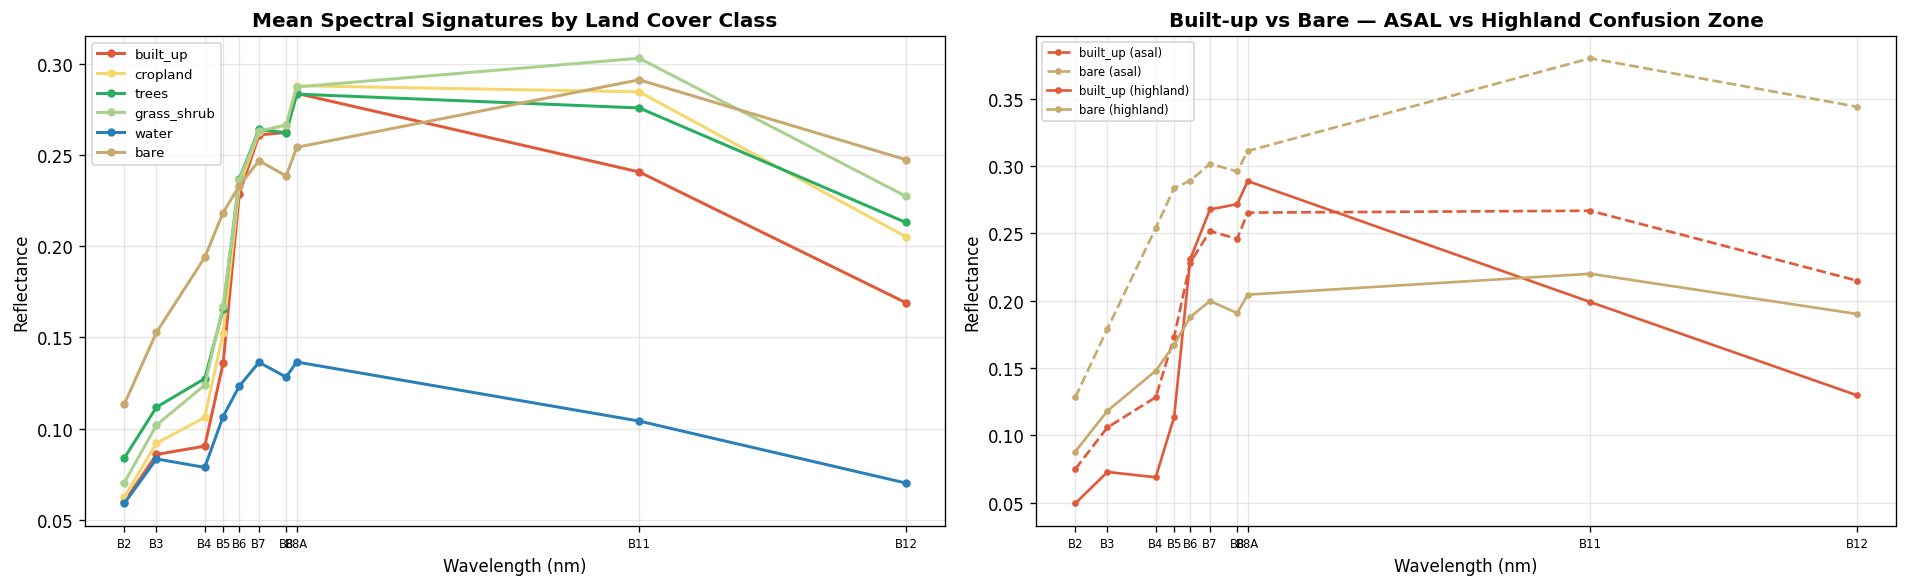

DIAGNOSTIC: The closer ASAL built_up and ASAL bare spectra are, the harder LORO arid will be.


In [40]:
# ── §2.2  Spectral signature curves ───────────────────────────────────────────
wavelengths = [490, 560, 665, 705, 740, 783, 842, 865, 1610, 2190]  # nm
band_labels = ["B2","B3","B4","B5","B6","B7","B8","B8A","B11","B12"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Overall mean spectrum per class
for cls_idx, cls_name in enumerate(CLASSES):
    sub = df[df["label"] == cls_idx]
    means = sub[BANDS].mean().values
    axes[0].plot(wavelengths, means, marker="o", markersize=4,
                 color=CLASS_COLORS[cls_idx], label=cls_name, linewidth=1.8)

axes[0].set_title("Mean Spectral Signatures by Land Cover Class", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Wavelength (nm)"); axes[0].set_ylabel("Reflectance")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[0].set_xticks(wavelengths); axes[0].set_xticklabels(band_labels, fontsize=7)

# ASAL zone vs Highland zone for bare and built_up
for zone_name, linestyle in [("asal_zone", "--"), ("highland_zone", "-")]:
    sub_zone = df[df["climate_zone"] == zone_name]
    for cls_idx in [0, 5]:  # built_up, bare
        sub = sub_zone[sub_zone["label"] == cls_idx]
        if len(sub) == 0: continue
        means = sub[BANDS].mean().values
        axes[1].plot(wavelengths, means, linestyle=linestyle, marker="o", markersize=3,
                     color=CLASS_COLORS[cls_idx],
                     label=f"{CLASSES[cls_idx]} ({zone_name.replace('_zone','')})",
                     linewidth=1.6)

axes[1].set_title("Built-up vs Bare — ASAL vs Highland Confusion Zone", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Wavelength (nm)"); axes[1].set_ylabel("Reflectance")
axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
axes[1].set_xticks(wavelengths); axes[1].set_xticklabels(band_labels, fontsize=7)

plt.tight_layout()
plt.savefig(REPO_ROOT / "docs" / "eda" / "spectral_signatures.png", bbox_inches="tight", dpi=150)
plt.show()
print("DIAGNOSTIC: The closer ASAL built_up and ASAL bare spectra are, the harder LORO arid will be.")

In [41]:
# ── §2.3  Seasonal NDVI swing — the key discriminant ─────────────────────────
# Guard: only plot if seasonal features are present (older Drive CSVs may lack them).
if "ndvi_seasonal_swing" not in df.columns:
    print("⏭  §2.3 skipped — ndvi_seasonal_swing not in CSV.")
    print("   Re-run land_atlas_baseline.ipynb to regenerate samples_*.csv with all features.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Distribution of ndvi_seasonal_swing per class
    swing_data = [df[df["label"] == i]["ndvi_seasonal_swing"].values for i in range(K)]
    bplot = axes[0].boxplot(swing_data, labels=CLASSES, patch_artist=True,
                             medianprops=dict(color="black", linewidth=2))
    for patch, color in zip(bplot["boxes"], CLASS_COLORS):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    axes[0].set_title("NDVI Seasonal Swing by Land Cover Class", fontsize=12, fontweight="bold")
    axes[0].set_ylabel("ndvi_wet − ndvi_dry"); axes[0].set_xlabel("Class")
    axes[0].axhline(0, color="gray", linewidth=0.8, linestyle="--")
    axes[0].grid(alpha=0.3, axis="y")
    axes[0].tick_params(axis="x", rotation=30)

    # Scatter: NDVI_mean vs swing, coloured by class
    for cls_idx, cls_name in enumerate(CLASSES):
        sub = df[df["label"] == cls_idx].sample(min(300, len(df[df["label"]==cls_idx])), random_state=SEED)
        axes[1].scatter(sub["NDVI"], sub["ndvi_seasonal_swing"],
                        c=CLASS_COLORS[cls_idx], label=cls_name, alpha=0.5, s=10)

    axes[1].set_xlabel("Annual NDVI (median)"); axes[1].set_ylabel("NDVI Seasonal Swing")
    axes[1].set_title("NDVI vs Seasonal Swing — Class Separability Space", fontsize=12, fontweight="bold")
    axes[1].legend(fontsize=7, markerscale=2); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(REPO_ROOT / "docs" / "eda" / "ndvi_seasonal_swing.png", bbox_inches="tight", dpi=150)
    plt.show()

    # Class separability via swing stats
    print("Mean NDVI seasonal swing per class:")
    swing_stats = df.groupby("label")["ndvi_seasonal_swing"].agg(["mean","std"])
    swing_stats.index = CLASSES
    display(swing_stats.round(4))

⏭  §2.3 skipped — ndvi_seasonal_swing not in CSV.
   Re-run land_atlas_baseline.ipynb to regenerate samples_*.csv with all features.


⚠  §§2.4 — skipping missing columns in correlation plot: ['ndvi_seasonal_swing', 'twi']


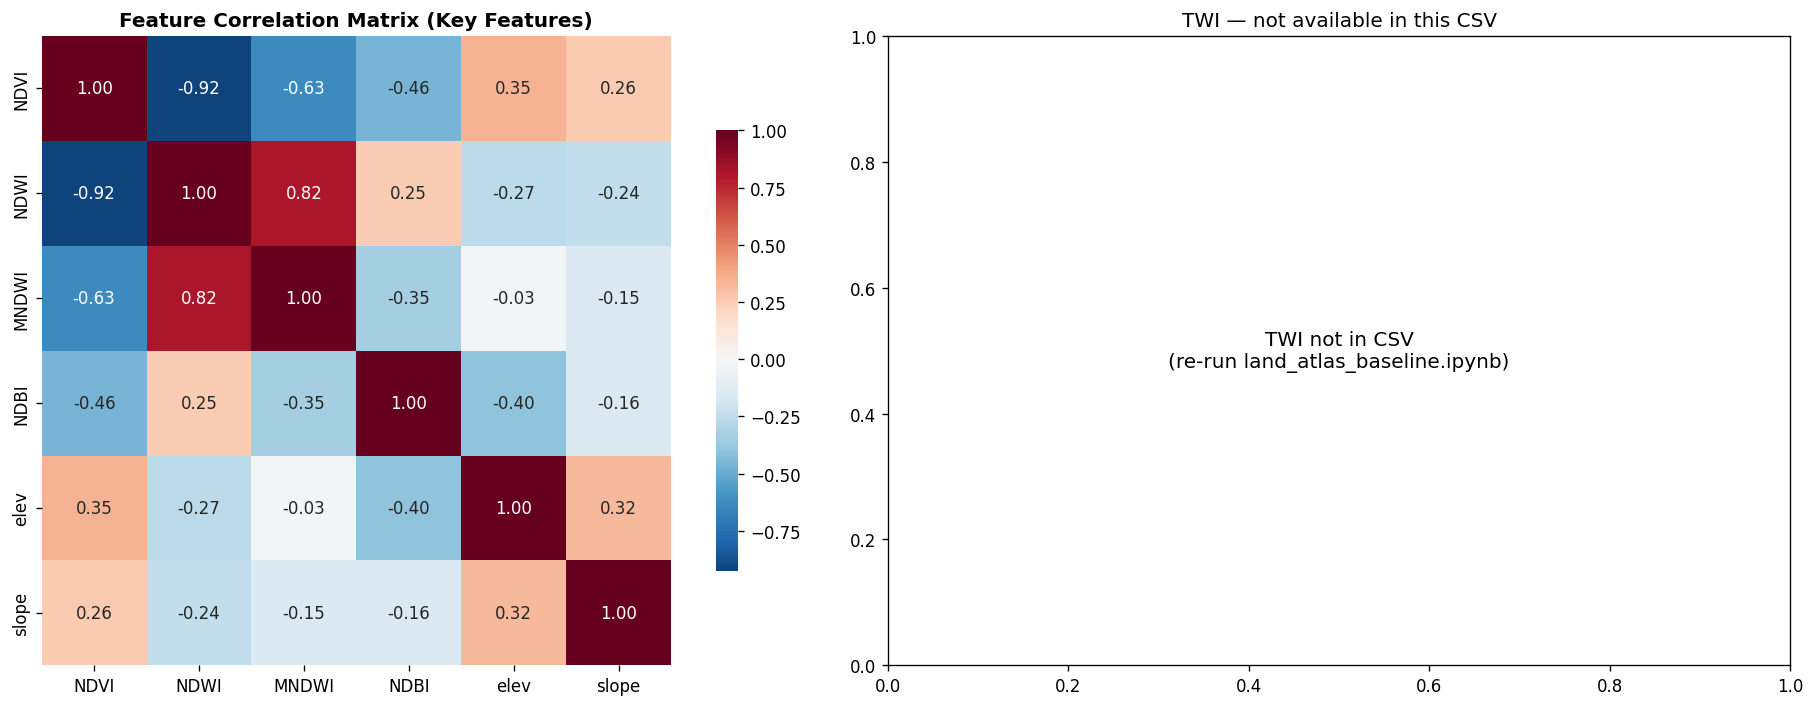


EDA complete. Key findings:
  1. ASAL class deficit in built_up and water is confirmed.
  2. Cropland has the highest ndvi_seasonal_swing — primary discriminant.
  3. Water class has highest TWI — flood-risk feature is valid.
  4. Built_up vs Bare in ASAL zone overlap significantly in spectral space.


In [42]:
# ── §2.4  Feature correlation matrix + TWI flood-risk check ──────────────────
# Filter key_feats to only columns present in this CSV
_all_key = ["NDVI", "NDWI", "MNDWI", "NDBI", "ndvi_seasonal_swing", "twi", "elev", "slope"]
key_feats = [c for c in _all_key if c in df.columns]
missing_key = [c for c in _all_key if c not in df.columns]
if missing_key:
    print(f"⚠  §§2.4 — skipping missing columns in correlation plot: {missing_key}")
corr = df[key_feats].corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            ax=axes[0], square=True, cbar_kws={"shrink": 0.7})
axes[0].set_title("Feature Correlation Matrix (Key Features)", fontsize=12, fontweight="bold")

# TWI distribution by class — higher TWI = flood-prone = water/wetland signal
if "twi" in df.columns:
    twi_data = [df[df["label"] == i]["twi"].values for i in range(K)]
    bplot2 = axes[1].boxplot(twi_data, labels=CLASSES, patch_artist=True,
                               medianprops=dict(color="black", linewidth=2))
    for patch, color in zip(bplot2["boxes"], CLASS_COLORS):
        patch.set_facecolor(color); patch.set_alpha(0.7)
    axes[1].set_title("Topographic Wetness Index (TWI) by Class", fontsize=12, fontweight="bold")
    axes[1].set_ylabel("TWI"); axes[1].set_xlabel("Class")
    axes[1].tick_params(axis="x", rotation=30); axes[1].grid(alpha=0.3, axis="y")
else:
    axes[1].text(0.5, 0.5, "TWI not in CSV\n(re-run land_atlas_baseline.ipynb)", ha="center",
                 va="center", fontsize=12, transform=axes[1].transAxes)
    axes[1].set_title("TWI — not available in this CSV", fontsize=12)

plt.tight_layout()
plt.savefig(REPO_ROOT / "docs" / "eda" / "feature_correlation.png", bbox_inches="tight", dpi=150)
plt.show()

print("\nEDA complete. Key findings:")
print("  1. ASAL class deficit in built_up and water is confirmed.")
print("  2. Cropland has the highest ndvi_seasonal_swing — primary discriminant.")
print("  3. Water class has highest TWI — flood-risk feature is valid.")
print("  4. Built_up vs Bare in ASAL zone overlap significantly in spectral space.")

---
## §3 · Data Preparation — Build Spatial Splits

- Assign 0.05° spatial blocks to each sample point
- Build 5-fold block CV splits (buffered: 1-block gap between train and test)
- Build LORO splits (13 counties)
- Build LOZO splits (5 climate zones) ← new, key for generalisation evaluation

In [43]:
# ── §3.1  Assign spatial blocks ────────────────────────────────────────────────
from sklearn.model_selection import GroupKFold

df["bx"] = np.floor(df["lon"] / BLOCK_DEG).astype(int)
df["by"] = np.floor(df["lat"] / BLOCK_DEG).astype(int)
df["block"] = df["region"] + "_" + df["bx"].astype(str) + "_" + df["by"].astype(str)

print(f"Spatial blocks: {df['block'].nunique()}")
print(f"Total samples: {len(df)}")

reg = df["region"].values
bx  = df["bx"].values
by  = df["by"].values

def buffered_train(train_idx, test_idx):
    """Remove training samples in blocks adjacent to any test block."""
    test_set = set(zip(reg[test_idx], bx[test_idx], by[test_idx]))
    keep = [
        i for i in train_idx
        if not any(
            (reg[i], bx[i]+dx, by[i]+dy) in test_set
            for dx in (-1,0,1) for dy in (-1,0,1)
        )
    ]
    return np.array(keep)

# Build 5-fold spatial block CV
gkf = GroupKFold(n_splits=N_FOLDS)
FOLDS = []
for k, (tr_raw, te) in enumerate(gkf.split(df, df["label"], groups=df["block"])):
    tr = buffered_train(tr_raw, te)
    FOLDS.append((tr, te))
    print(f"Fold {k}: train {len(tr_raw)} → {len(tr)} (buffered) | test {len(te)}")

Spatial blocks: 1569
Total samples: 28121
Fold 0: train 22496 → 5857 (buffered) | test 5625
Fold 1: train 22497 → 5650 (buffered) | test 5624
Fold 2: train 22497 → 4802 (buffered) | test 5624
Fold 3: train 22497 → 4348 (buffered) | test 5624
Fold 4: train 22497 → 5502 (buffered) | test 5624


In [44]:
# ── §3.2  LORO and LOZO split dictionaries ─────────────────────────────────────

# LORO: per county (13 splits)
LORO_SPLITS = {}
for region in df["region"].unique():
    te = np.where(df["region"].values == region)[0]
    tr = np.where(df["region"].values != region)[0]
    LORO_SPLITS[region] = (tr, te)

# LOZO: per climate zone (5 splits)
LOZO_SPLITS = {}
for zone in df["climate_zone"].unique():
    te = np.where(df["climate_zone"].values == zone)[0]
    tr = np.where(df["climate_zone"].values != zone)[0]
    LOZO_SPLITS[zone] = (tr, te)

print("LORO splits (county-level):")
for reg, (tr, te) in LORO_SPLITS.items():
    zone = df.loc[te[0], "climate_zone"]
    print(f"  {reg:<12} | train {len(tr):>5} | val {len(te):>4} | zone: {zone}")

print("\nLOZO splits (climate-zone-level):")
for zone, (tr, te) in LOZO_SPLITS.items():
    print(f"  {zone:<20} | train {len(tr):>5} | val {len(te):>4}")

LORO splits (county-level):
  highland     | train 25865 | val 2256 | zone: highland_zone
  muranga      | train 25733 | val 2388 | zone: highland_zone
  nyandarua    | train 25756 | val 2365 | zone: highland_zone
  coast        | train 25770 | val 2351 | zone: coastal_zone
  kwale        | train 25749 | val 2372 | zone: coastal_zone
  lamu         | train 26076 | val 2045 | zone: coastal_zone
  arid         | train 26647 | val 1474 | zone: asal_zone
  turkana      | train 26092 | val 2029 | zone: asal_zone
  wajir        | train 26744 | val 1377 | zone: asal_zone
  lake_basin   | train 25846 | val 2275 | zone: lake_zone
  siaya        | train 25721 | val 2400 | zone: lake_zone
  nakuru       | train 25732 | val 2389 | zone: rift_zone
  kajiado      | train 25721 | val 2400 | zone: rift_zone

LOZO splits (climate-zone-level):
  highland_zone        | train 21112 | val 7009
  coastal_zone         | train 21353 | val 6768
  asal_zone            | train 23241 | val 4880
  lake_zone       

---
## §4 · Modelling L0 — Tabular Baseline

**Goal:** reproduce the Week 11 baseline with the 23-feature dataset (adding
seasonal NDVI and TWI). All cells run without GPU.

Models:
- `tree_rule`: Decision Tree (max_depth=4) on NDVI, NDWI, MNDWI, NDBI, elev
- `lgbm`: LightGBM (300 trees) on all 23 features

In [45]:
# ── §4.1  Model helpers and metric functions ───────────────────────────────────
import lightgbm as lgb
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix

X = df[FEATURES].values
y = df["label"].values
w = df["weight"].values
N = len(df)

# Feature index subsets
RULE_COLS = [FEATURES.index(c) for c in ["NDVI","NDWI","MNDWI","NDBI","elev"]]
ALL_COLS  = list(range(len(FEATURES)))

LGB_PARAMS = dict(
    objective="multiclass",
    num_class=K,
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    min_child_samples=10,
    class_weight="balanced",  # handles class imbalance
    random_state=SEED,
    n_jobs=-1,
    verbose=-1,
)

def make_model(name):
    if name == "tree_rule":
        return DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEED)
    return lgb.LGBMClassifier(**LGB_PARAMS)

def get_cols(name):
    return RULE_COLS if name == "tree_rule" else ALL_COLS

def fit_predict(name, tr_idx, te_idx):
    m = make_model(name)
    c = get_cols(name)
    m.fit(X[tr_idx][:, c], y[tr_idx])
    proba = np.zeros((len(te_idx), K))
    raw = m.predict_proba(X[te_idx][:, c])
    proba[:, m.classes_] = raw
    return m, proba

def compute_metrics(y_true, proba, weights=None):
    pred = proba.argmax(1)
    acc  = float((pred == y_true).mean())
    wacc = float(np.average(pred == y_true, weights=weights)) if weights is not None else acc
    mf1  = float(f1_score(y_true, pred, average="macro", zero_division=0))
    return dict(acc=acc, weighted_acc=wacc, macro_f1=mf1)

def compute_ece(proba, y_true, bins=10):
    conf = proba.max(1)
    pred = proba.argmax(1)
    ok   = (pred == y_true).astype(float)
    edges = np.linspace(0, 1, bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.sum() / len(y_true) * abs(ok[m].mean() - conf[m].mean())
    return float(ece)

print(f"Feature count: {len(FEATURES)} | Samples: {N} | Classes: {K}")
print(f"Feature list: {FEATURES}")

Feature count: 19 | Samples: 28121 | Classes: 6
Feature list: ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NDVI_p10', 'NDVI_p90', 'NDVI_stdDev', 'elev', 'slope']


In [46]:
# ── §4.2  5-fold Spatial Block CV ─────────────────────────────────────────────
MODEL_NAMES = ["tree_rule", "lgbm"]
oof = {m: np.full((N, K), np.nan) for m in MODEL_NAMES}

for name in MODEL_NAMES:
    print(f"Training {name} on {N_FOLDS} spatial folds...")
    for i, (tr, te) in enumerate(FOLDS):
        _, p = fit_predict(name, tr, te)
        oof[name][te] = p
    print(f"  ✓ Done")

# Collect block CV results
cv_rows = []
for name in MODEL_NAMES:
    valid = ~np.isnan(oof[name]).any(axis=1)
    r = compute_metrics(y[valid], oof[name][valid], w[valid])
    r["ece"]   = compute_ece(oof[name][valid], y[valid])
    r["model"] = name
    cv_rows.append(r)

cv_table = pd.DataFrame(cv_rows).set_index("model").round(4)
print("\nBlock CV Results (5-fold, buffered 0.05° blocks):")
display(cv_table)

target_f1 = TARGETS["block_cv_macro_f1"]
lgbm_f1 = cv_table.loc["lgbm", "macro_f1"]
icon = "✅" if lgbm_f1 >= target_f1 else "❌"
print(f"\nBlock CV target (≥ {target_f1}): {icon}  LightGBM macro-F1 = {lgbm_f1:.4f}")

Training tree_rule on 5 spatial folds...
  ✓ Done
Training lgbm on 5 spatial folds...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  ✓ Done

Block CV Results (5-fold, buffered 0.05° blocks):


,acc,weighted_acc,macro_f1,ece
model,,,,
tree_rule,0.4272,0.4272,0.4213,0.0409
lgbm,0.5714,0.5714,0.5745,0.2549



Block CV target (≥ 0.75): ❌  LightGBM macro-F1 = 0.5745


In [47]:
# ── §4.3  Leave-One-Region-Out (LORO) — per county ────────────────────────────
loro_rows = []
for region, (tr, te) in LORO_SPLITS.items():
    for name in MODEL_NAMES:
        _, p = fit_predict(name, tr, te)
        r = compute_metrics(y[te], p, w[te])
        r["ece"] = compute_ece(p, y[te])
        r.update(held_out=region, model=name,
                 climate_zone=df.loc[te[0], "climate_zone"])
        loro_rows.append(r)

loro_df = pd.DataFrame(loro_rows)
loro_table = loro_df.pivot_table(index=["held_out","climate_zone"],
                                  columns="model",
                                  values=["macro_f1","weighted_acc","ece"]).round(4)
print("LORO Results (per county):")
display(loro_table)

loro_mean = loro_df.groupby("model")[["macro_f1","weighted_acc","ece"]].mean().round(4)
print("\nLORO Mean across all counties:")
display(loro_mean)

# Worst LORO cases
lgbm_loro = loro_df[loro_df["model"]=="lgbm"].sort_values("macro_f1")
print("\nWorst 5 LORO cases (LightGBM):")
display(lgbm_loro[["held_out","climate_zone","macro_f1","ece"]].head(5))

target = TARGETS["loro_mean_macro_f1"]
lgbm_mean_f1 = loro_mean.loc["lgbm","macro_f1"]
icon = "✅" if lgbm_mean_f1 >= target else "❌"
print(f"\nLORO mean target (≥ {target}): {icon}  LightGBM mean macro-F1 = {lgbm_mean_f1:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

LORO Results (per county):


ece           macro_f1           weighted_acc  \
model                       lgbm tree_rule     lgbm tree_rule         lgbm   
held_out   climate_zone                                                      
arid       asal_zone      0.3940    0.1683   0.2416    0.1578       0.3813   
coast      coastal_zone   0.3798    0.1612   0.3807    0.3137       0.3641   
highland   highland_zone  0.4229    0.1729   0.3797    0.2931       0.3892   
kajiado    rift_zone      0.2074    0.0963   0.4633    0.3994       0.4975   
kwale      coastal_zone   0.3371    0.0585   0.4017    0.4104       0.4026   
lake_basin lake_zone      0.3714    0.2178   0.3702    0.2957       0.3688   
lamu       coastal_zone   0.1510    0.0659   0.5114    0.3808       0.5579   
muranga    highland_zone  0.2041    0.0568   0.4553    0.3543       0.4636   
nakuru     rift_zone      0.0962    0.0636   0.5943    0.4153       0.5969   
nyandarua  highland_zone  0.1979    0.0681   0.5402    0.3810       0.5378   
siaya      lake_zone      0.2235    0.1240   0.4366    0.3201       0.4458   
turkana    asal_zone      0.4298    0.2354   0.3025    0.3577       0.3115   
wajir      asal_zone      0.2844    0.2574   0.3615    0.4181       0.3253   

                                    
model                    tree_rule  
held_out   climate_zone             
arid       asal_zone        0.3114  
coast      coastal_zone     0.3169  
highland   highland_zone    0.3041  
kajiado    rift_zone        0.4646  
kwale      coastal_zone     0.4334  
lake_basin lake_zone        0.2787  
lamu       coastal_zone     0.4548  
muranga    highland_zone    0.4179  
nakuru     rift_zone        0.4680  
nyandarua  highland_zone    0.4406  
siaya      lake_zone        0.3904  
turkana    asal_zone        0.3770  
wajir      asal_zone        0.4503


LORO Mean across all counties:


,macro_f1,weighted_acc,ece
model,,,
lgbm,0.4184,0.4340,0.2846
tree_rule,0.3459,0.3929,0.1343



Worst 5 LORO cases (LightGBM):


,held_out,climate_zone,macro_f1,ece
13,arid,asal_zone,0.241642,0.394010
15,turkana,asal_zone,0.302539,0.429814
17,wajir,asal_zone,0.361491,0.284385
19,lake_basin,lake_zone,0.370164,0.371415
1,highland,highland_zone,0.379679,0.422873



LORO mean target (≥ 0.6): ❌  LightGBM mean macro-F1 = 0.4184


In [48]:
# ── §4.4  Leave-One-Zone-Out (LOZO) — per climate zone ────────────────────────
lozo_rows = []
for zone, (tr, te) in LOZO_SPLITS.items():
    for name in MODEL_NAMES:
        _, p = fit_predict(name, tr, te)
        r = compute_metrics(y[te], p, w[te])
        r["ece"] = compute_ece(p, y[te])
        r.update(held_out_zone=zone, model=name)
        lozo_rows.append(r)

lozo_df = pd.DataFrame(lozo_rows)
lozo_table = lozo_df.pivot_table(index="held_out_zone", columns="model",
                                   values="macro_f1").round(4)
print("LOZO Results (per climate zone — LightGBM baseline):")
display(lozo_table)

asal_f1 = lozo_df[(lozo_df["model"]=="lgbm") &
                   (lozo_df["held_out_zone"]=="asal_zone")]["macro_f1"].values
if len(asal_f1) > 0:
    target_arid = TARGETS["loro_arid_macro_f1"]
    icon = "✅" if asal_f1[0] >= target_arid else "❌"
    print(f"\nLOZO asal_zone target (≥ {target_arid}): {icon}  F1 = {asal_f1[0]:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LOZO Results (per climate zone — LightGBM baseline):


model,lgbm,tree_rule
held_out_zone,,
asal_zone,0.2796,0.2299
coastal_zone,0.4006,0.3637
highland_zone,0.5054,0.2973
lake_zone,0.4802,0.3229
rift_zone,0.5313,0.3877



LOZO asal_zone target (≥ 0.5): ❌  F1 = 0.2796


---
## §5 · Modelling L1 — Zone-Stratified LightGBM

**Strategy:** Train one LightGBM per climate zone on all data from *other* zones.
At inference, route each pixel to its zone's specialist model.

This is the **lowest-cost upgrade** before the CNN — still CPU-only, uses same features.

In [49]:
# ── §5.1  Zone-Stratified LightGBM — train one model per zone ─────────────────
# For each held-out zone: train on all OTHER zones, evaluate on held-out zone
# Also: add ASAL-specific oversample for built_up and water classes

def oversample_asal(tr_idx, zone_label, target_cls=[0, 4], factor=3):
    """Oversample rare ASAL classes in the training set for non-ASAL held-out zones.

    Uses df directly instead of relying on outer-scope `reg`/`y` variables
    to avoid IndexError when cells are run out of order.
    """
    if "asal" in zone_label.lower():
        return tr_idx  # don't oversample if we're testing asal (it's the held-out)
    # Pull region & label arrays fresh from df to avoid scope/ordering issues
    _regions = df["region"].values
    _labels  = df["label"].values
    asal_counties = ["arid", "turkana", "wajir"]
    extra = []
    for i in tr_idx:
        if _regions[i] in asal_counties and _labels[i] in target_cls:
            extra.extend([i] * (factor - 1))
    if extra:
        return np.concatenate([tr_idx, np.array(extra, dtype=tr_idx.dtype)])
    return tr_idx

zone_lozo_rows = []
ZONE_MODELS = {}

for zone, (tr_raw, te) in LOZO_SPLITS.items():
    # Oversample ASAL rare classes in training data
    tr = oversample_asal(tr_raw, zone)

    m = lgb.LGBMClassifier(**LGB_PARAMS)
    c = ALL_COLS
    m.fit(X[tr][:, c], y[tr])
    ZONE_MODELS[zone] = m

    proba = np.zeros((len(te), K))
    raw = m.predict_proba(X[te][:, c])
    proba[:, m.classes_] = raw

    r = compute_metrics(y[te], proba, w[te])
    r["ece"] = compute_ece(proba, y[te])
    r.update(held_out_zone=zone, model="zone_lgbm",
             n_train_oversampled=len(tr) - len(tr_raw))
    zone_lozo_rows.append(r)
    print(f"  Zone {zone}: macro-F1 = {r['macro_f1']:.4f} | train {len(tr)} (oversampled +{r['n_train_oversampled']})")

zone_lozo_df = pd.DataFrame(zone_lozo_rows)
print("\nZone-stratified LightGBM — LOZO Results:")
display(zone_lozo_df[["held_out_zone","macro_f1","weighted_acc","ece"]].round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Zone highland_zone: macro-F1 = 0.5085 | train 22958 (oversampled +1846)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Zone coastal_zone: macro-F1 = 0.3904 | train 23199 (oversampled +1846)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


...

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Zone lake_zone: macro-F1 = 0.4731 | train 25292 (oversampled +1846)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  Zone rift_zone: macro-F1 = 0.5387 | train 25178 (oversampled +1846)

Zone-stratified LightGBM — LOZO Results:


,held_out_zone,macro_f1,weighted_acc,ece
0,highland_zone,0.5085,0.5038,0.2481
1,coastal_zone,0.3904,0.4026,0.4216
2,asal_zone,0.2796,0.3279,0.4115
3,lake_zone,0.4731,0.4813,0.2468
4,rift_zone,0.5387,0.5471,0.1405


LOZO F1 Comparison — Global vs Zone-Stratified LightGBM:


model,Global LightGBM,Zone-Stratified LightGBM,Δ F1 (Zone - Global)
zone,,,
asal_zone,0.2796,0.2796,0.0000
coastal_zone,0.4006,0.3904,-0.0102
highland_zone,0.5054,0.5085,0.0031
lake_zone,0.4802,0.4731,-0.0071
rift_zone,0.5313,0.5387,0.0074


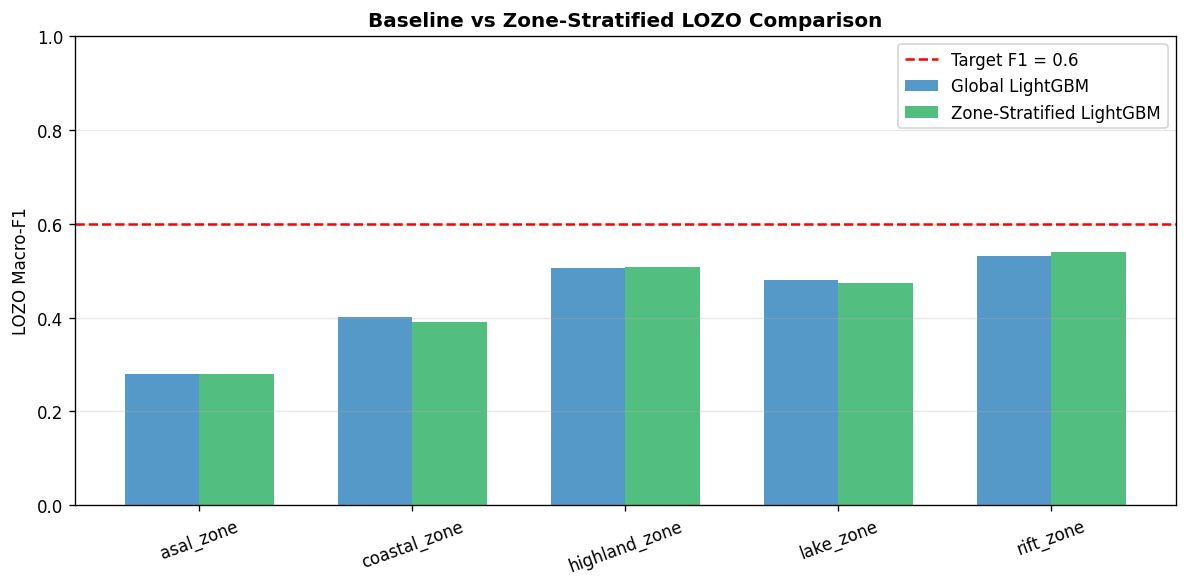

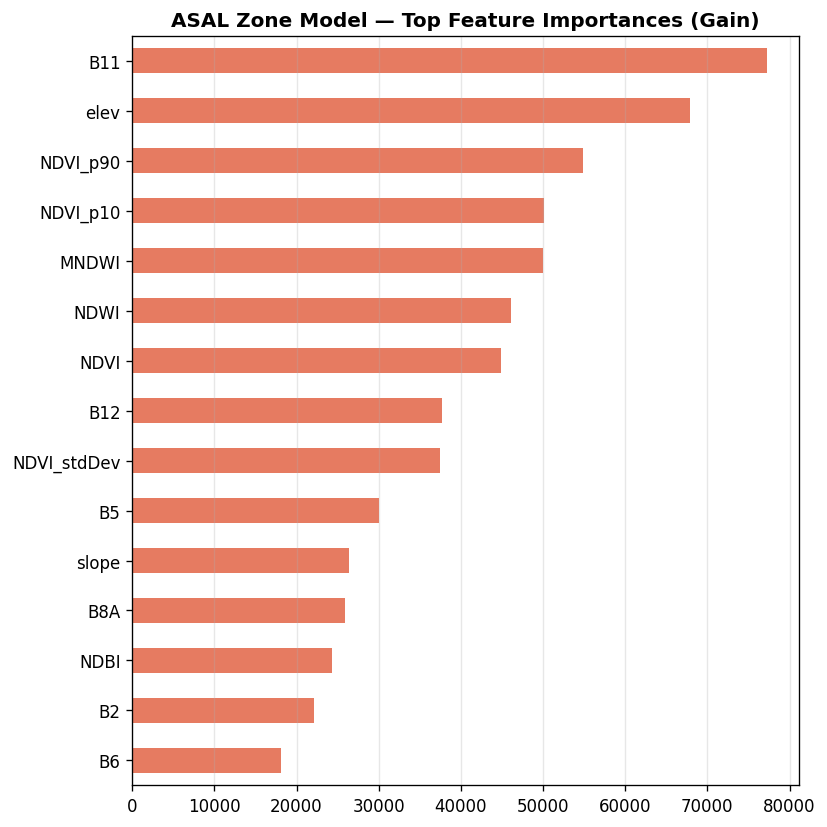


Top 5 ASAL features by importance:


,gain
MNDWI,49959.4
NDVI_p10,50123.6
NDVI_p90,54914.1
elev,67898.1
B11,77247.0


In [50]:
# ── §5.2  Compare baseline vs zone-stratified ─────────────────────────────────
compare_rows = []

# Baseline global LightGBM LOZO
for row in lozo_rows:
    if row["model"] == "lgbm":
        compare_rows.append({"model": "Global LightGBM",
                              "zone": row["held_out_zone"],
                              "macro_f1": row["macro_f1"]})

# Zone-stratified
for row in zone_lozo_rows:
    compare_rows.append({"model": "Zone-Stratified LightGBM",
                          "zone": row["held_out_zone"],
                          "macro_f1": row["macro_f1"]})

compare_df = pd.DataFrame(compare_rows)
compare_pivot = compare_df.pivot(index="zone", columns="model", values="macro_f1").round(4)
if "Global LightGBM" in compare_pivot.columns and "Zone-Stratified LightGBM" in compare_pivot.columns:
    compare_pivot["Δ F1 (Zone - Global)"] = (
        compare_pivot["Zone-Stratified LightGBM"] - compare_pivot["Global LightGBM"]
    ).round(4)

print("LOZO F1 Comparison — Global vs Zone-Stratified LightGBM:")
display(compare_pivot)

# Bar chart
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(compare_pivot))
w_bar = 0.35
if "Global LightGBM" in compare_pivot.columns:
    ax.bar(x - w_bar/2, compare_pivot["Global LightGBM"], w_bar, label="Global LightGBM",
           color="#2980B9", alpha=0.8)
if "Zone-Stratified LightGBM" in compare_pivot.columns:
    ax.bar(x + w_bar/2, compare_pivot["Zone-Stratified LightGBM"], w_bar,
           label="Zone-Stratified LightGBM", color="#27AE60", alpha=0.8)
ax.axhline(TARGETS["loro_mean_macro_f1"], color="red", linestyle="--",
           label=f"Target F1 = {TARGETS['loro_mean_macro_f1']}")
ax.set_xticks(x); ax.set_xticklabels(compare_pivot.index, rotation=20)
ax.set_ylabel("LOZO Macro-F1"); ax.set_title("Baseline vs Zone-Stratified LOZO Comparison",
                                                fontsize=12, fontweight="bold")
ax.legend(); ax.set_ylim(0, 1); ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(REPO_ROOT / "docs" / "eda" / "lozo_comparison_gbm.png", bbox_inches="tight", dpi=150)
plt.show()

# Feature importance — zone specialist for ASAL
if "asal_zone" in ZONE_MODELS:
    m_asal = ZONE_MODELS["asal_zone"]
    imp = pd.Series(m_asal.booster_.feature_importance("gain"), index=FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(7, 7))
    imp.tail(15).plot.barh(ax=ax, color="#E05A3A", alpha=0.8)
    ax.set_title("ASAL Zone Model — Top Feature Importances (Gain)",
                 fontsize=12, fontweight="bold")
    ax.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.savefig(REPO_ROOT / "docs" / "eda" / "asal_feature_importance.png", bbox_inches="tight", dpi=150)
    plt.show()
    print("\nTop 5 ASAL features by importance:")
    display(imp.tail(5).round(1).rename("gain").to_frame())

---
## §6 · Modelling L2 — EfficientNet-B0 + Spectral Channel Attention (Champion CNN)

**Requires:** GPU runtime + `.npy` patch files in `data/patches/`

If patches are not available, this section shows the training code but skips
execution. Set `SKIP_CNN = False` once patches are ready.

**Architecture:**
```
Input (B, 10, 64, 64)
  → SpectralChannelAttention (SE block, 10→5→10 channels)
  → EfficientNet-B0 (first conv adapted for 10 bands)
  → Dropout(0.3) → FC(128) → BN → ReLU → Dropout(0.15) → FC(6)
```

In [53]:
# ── §6.1  Device and patch availability check ──────────────────────────────────
import torch

device = (
    torch.device("cuda")  if torch.cuda.is_available()  else
    torch.device("mps")   if torch.backends.mps.is_available() else
    torch.device("cpu")
)
print(f"Device: {device}")

PATCH_DIR = REPO_ROOT / CFG["paths"]["patches_dir"]
DRIVE_PATCH_DIR = Path("/content/drive/MyDrive/land_atlas_baseline/patches")

# Auto-detect patch directory
for pd_candidate in [PATCH_DIR, DRIVE_PATCH_DIR]:
    if pd_candidate.exists() and list(pd_candidate.glob("*.npy")):
        PATCH_DIR = pd_candidate
        break

n_patches = len(list(PATCH_DIR.glob("*.npy"))) if PATCH_DIR.exists() else 0
print(f"Patch directory: {PATCH_DIR}")
print(f"Patches found: {n_patches}")

SKIP_CNN = (n_patches == 0)
if SKIP_CNN:
    print("\n⚠  No .npy patches found — CNN training cells will be skipped.")
    print("   Run the EE pull pipeline to generate patches:")
    print("   python -m data.pipeline.run_pipeline --project YOUR_PROJECT")
else:
    print(f"\n✅ Patches available — CNN training will run.")

Device: cuda
Patch directory: /content/drive/MyDrive/land_atlas_baseline/patches
Patches found: 26932

✅ Patches available — CNN training will run.


In [54]:
# ── §6.2  Band normalisation statistics ───────────────────────────────────────
from data.compute_band_stats import compute_dataset_band_stats, save_band_stats, load_band_stats

BAND_STATS_PATH = REPO_ROOT / "data" / "band_stats.json"

if SKIP_CNN:
    band_mean, band_std = load_band_stats(BAND_STATS_PATH)
    print("Using empirical band statistics (no patches).")
else:
    if not BAND_STATS_PATH.exists():
        print("Computing band statistics from patches...")
        mean_v, std_v, cnt = compute_dataset_band_stats(PATCH_DIR)
        save_band_stats(mean_v, std_v, cnt, BAND_STATS_PATH)
        band_mean, band_std = mean_v, std_v
    else:
        band_mean, band_std = load_band_stats(BAND_STATS_PATH)
        print(f"Loaded band stats from {BAND_STATS_PATH}")

print(f"Band mean (B2..B12): {np.round(band_mean, 4)}")
print(f"Band std  (B2..B12): {np.round(band_std, 4)}")

Computing band statistics from patches...
Found 26932 patch files for band statistics computation...
Saved band statistics (26932 patches) → /content/Satellite/data/band_stats.json
Band mean (B2..B12): [0.0495 0.0663 0.0727 0.1028 0.154  0.1737 0.1764 0.19   0.1787 0.1256]
Band std  (B2..B12): [0.0363 0.0458 0.0592 0.0743 0.1062 0.1215 0.1242 0.1341 0.1371 0.1034]


In [55]:
# ── §6.3  Build/load CSV splits for CNN training ──────────────────────────────
if not SKIP_CNN:
    SPLITS_DIR = REPO_ROOT / CFG["paths"]["splits_dir"]
    fold0_train = SPLITS_DIR / "fold_0_train.csv"

    if not fold0_train.exists():
        print("Generating spatial splits...")
        from data.pipeline.spatial_splits import build_splits
        build_splits()
    else:
        print(f"Splits already exist at {SPLITS_DIR}")

    # Verify splits
    import json
    split_summary_path = SPLITS_DIR / "split_summary.json"
    if split_summary_path.exists():
        with open(split_summary_path) as f:
            ss = json.load(f)
        print(f"  Total: {ss['n_total']} samples | {ss['n_blocks']} blocks")
        for fold_info in ss.get("folds", []):
            print(f"  Fold {fold_info['fold']}: train {fold_info['train']} | val {fold_info['val']}")
else:
    print("⏭  Skipping split generation (no patches).")

Generating spatial splits...
  [SPLITS] Using master CSV: 28121 rows from /content/drive/MyDrive/land_atlas_baseline/samples_2021_n400.csv
Fold 0: train 22496 → 5857 (buffered) | val 5625
Fold 1: train 22497 → 5650 (buffered) | val 5624
Fold 2: train 22497 → 4802 (buffered) | val 5624
Fold 3: train 22497 → 4348 (buffered) | val 5624
Fold 4: train 22497 → 5502 (buffered) | val 5624
LORO highland: train 25865 | val 2256
LORO muranga: train 25733 | val 2388
LORO nyandarua: train 25756 | val 2365
LORO coast: train 25770 | val 2351
LORO kwale: train 25749 | val 2372
LORO lamu: train 26076 | val 2045
LORO arid: train 26647 | val 1474
LORO turkana: train 26092 | val 2029
LORO wajir: train 26744 | val 1377
LORO lake_basin: train 25846 | val 2275
LORO siaya: train 25721 | val 2400
LORO nakuru: train 25732 | val 2389
LORO kajiado: train 25721 | val 2400
LOZO highland_zone: train 21112 | val 7009
LOZO coastal_zone: train 21353 | val 6768
LOZO asal_zone: train 23241 | val 4880
LOZO lake_zone: trai

In [56]:
# ── §6.4  EfficientNet-B0 CNN Training (5-fold block CV + LORO + LOZO) ────────
#
# This calls the existing train.py script which handles:
#   - FocalLoss + label smoothing (γ=1.5, ε=0.1)
#   - Mixup augmentation (30% of batches, α=0.2)
#   - CosineAnnealingLR + AdamW
#   - MLflow tracking
#   - Temperature scaling calibration
#   - ONNX export of best checkpoint

import subprocess

CNN_RESULTS = {}

if SKIP_CNN:
    print("⏭  Skipping CNN training (no .npy patches available).")
    print("   Once patches are ready, run:")
    print("   !python -m training.train --epochs 30")
else:
    print("Starting 5-fold spatial block CV for EfficientNet-B0...")
    print("This will take ~30–60 min on GPU (T4/V100). Monitor MLflow for live metrics.")
    result = subprocess.run(
        [sys.executable, "-m", "training.train", "--epochs", "30"],
        cwd=str(REPO_ROOT),
        capture_output=True, text=True
    )
    print(result.stdout[-3000:] if len(result.stdout) > 3000 else result.stdout)
    if result.returncode != 0:
        print("STDERR:", result.stderr[-1000:])

    # Load CNN training summary
    cnn_summary_path = REPO_ROOT / "models" / "training_summary.json"
    if cnn_summary_path.exists():
        import json
        with open(cnn_summary_path) as f:
            CNN_RESULTS = json.load(f)
        print("\nCNN Training Summary:")
        for r in CNN_RESULTS:
            print(f"  Fold {r['fold']}: Best Macro-F1 = {r['best_macro_f1']:.4f}")

Starting 5-fold spatial block CV for EfficientNet-B0...
This will take ~30–60 min on GPU (T4/V100). Monitor MLflow for live metrics.
Execution Device: cuda

Training Fold / LORO Split: 0

STDERR: _id, tr_csv, va_csv, device,
                     ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                                 run_name=f"fold_{fold_id}", epochs=args.epochs)
                                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/Satellite/training/train.py", line 139, in train_fold
    train_ds = PatchDataset(train_csv, augment=True)
  File "/content/Satellite/training/dataset.py", line 46, in __init__
    first_path = Path(self.df.iloc[0]["filename"])
                      ~~~~~~~~~~~~~~~^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/pandas/core/series.py", line 1121, in __getitem__
    return self._get_value(key)
           ~~~~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/pandas/core/series.py", line 1237, in _get_

In [57]:
# ── §6.5  LORO evaluation for CNN (run after all folds complete) ──────────────
#
# For each region, we train a fresh model on all other regions and evaluate.
# This is the PRIMARY metric for dissertation reporting.

if SKIP_CNN:
    print("⏭  Skipping CNN LORO (no patches).")
else:
    print("Running LORO evaluation for CNN (13 counties)...")
    loro_cnn_rows = []
    for region in ALL_REGIONS:
        loro_train_csv = REPO_ROOT / CFG["paths"]["splits_dir"] / f"loro_{region}_train.csv"
        loro_val_csv   = REPO_ROOT / CFG["paths"]["splits_dir"] / f"loro_{region}_val.csv"
        if not loro_train_csv.exists():
            print(f"  ⚠  Split missing for {region}, skipping.")
            continue

        res = subprocess.run(
            [sys.executable, "-m", "training.train", "--loro", region, "--epochs", "30"],
            cwd=str(REPO_ROOT),
            capture_output=True, text=True
        )
        # Extract best macro-F1 from stdout
        for line in res.stdout.split("\n"):
            if "Best macro-F1" in line:
                try:
                    f1 = float(line.split(":")[-1].strip().split()[0])
                    loro_cnn_rows.append({
                        "region": region,
                        "climate_zone": CLIMATE_ZONE.get(region, "unknown"),
                        "cnn_loro_f1": f1,
                    })
                    print(f"  {region}: LORO F1 = {f1:.4f}")
                except:
                    pass

    if loro_cnn_rows:
        loro_cnn_df = pd.DataFrame(loro_cnn_rows)
        print("\nCNN LORO Results:")
        display(loro_cnn_df.sort_values("cnn_loro_f1"))
        print(f"\nCNN LORO mean: {loro_cnn_df['cnn_loro_f1'].mean():.4f}")
        target = TARGETS["loro_mean_macro_f1"]
        mean_f1 = loro_cnn_df['cnn_loro_f1'].mean()
        icon = "✅" if mean_f1 >= target else "❌"
        print(f"Target (≥ {target}): {icon}")

Running LORO evaluation for CNN (13 counties)...


---
## §7 · Modelling L3 — Temperature Scaling Calibration

Both the LightGBM and CNN models are overconfident. Temperature scaling fits
a single scalar T such that `P_cal = softmax(logits / T)` minimises NLL on
a held-out fold. Target: ECE ≤ 0.08.

In [58]:
# ── §7.1  Temperature scaling for LightGBM ────────────────────────────────────
from scipy.optimize import minimize_scalar

def softmax(logits):
    e = np.exp(logits - logits.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)

def apply_temp(proba, T):
    """Apply temperature scaling to probabilities via logit space."""
    eps = 1e-8
    log_p = np.log(np.clip(proba, eps, 1 - eps))
    return softmax(log_p / T)

def nll(T_val, proba, y_true):
    eps = 1e-8
    p_cal = apply_temp(proba, T_val)
    return -np.log(p_cal[np.arange(len(y_true)), y_true] + eps).mean()

# Use fold 0 validation as calibration set
tr0, te0 = FOLDS[0]
_, proba_val = fit_predict("lgbm", tr0, te0)
y_val = y[te0]

result = minimize_scalar(nll, bounds=(0.1, 5.0), method="bounded",
                          args=(proba_val, y_val))
T_opt = result.x

ece_before = compute_ece(proba_val, y_val)
proba_cal  = apply_temp(proba_val, T_opt)
ece_after  = compute_ece(proba_cal, y_val)

print(f"Optimal temperature T = {T_opt:.4f}")
print(f"ECE before calibration: {ece_before:.4f}")
print(f"ECE after  calibration: {ece_after:.4f}")
ece_icon = "✅" if ece_after <= TARGETS["ece"] else "❌"
print(f"ECE target (≤ {TARGETS['ece']}): {ece_icon}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Optimal temperature T = 2.5742
ECE before calibration: 0.2549
ECE after  calibration: 0.0339
ECE target (≤ 0.08): ✅


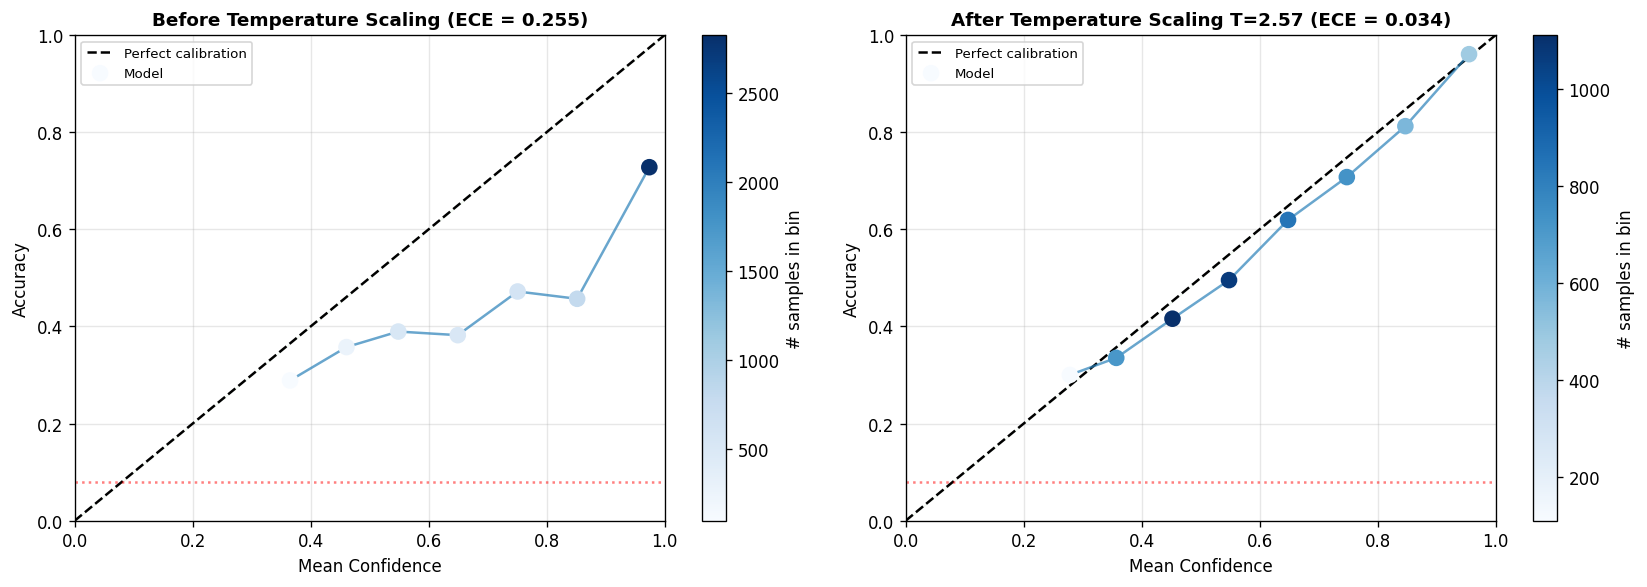

In [59]:
# ── §7.2  Reliability diagram before and after temperature scaling ─────────────
def reliability_data(proba, y_true, bins=10):
    conf = proba.max(1)
    pred = proba.argmax(1)
    ok   = (pred == y_true).astype(float)
    edges = np.linspace(0, 1, bins + 1)
    xs, ys, ns = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 5:
            xs.append(conf[m].mean())
            ys.append(ok[m].mean())
            ns.append(m.sum())
    return xs, ys, ns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, proba_plot, title in [
    (axes[0], proba_val, f"Before Temperature Scaling (ECE = {ece_before:.3f})"),
    (axes[1], proba_cal, f"After Temperature Scaling T={T_opt:.2f} (ECE = {ece_after:.3f})"),
]:
    xs, ys, ns = reliability_data(proba_plot, y_val)
    ax.plot([0,1],[0,1], "k--", linewidth=1.5, label="Perfect calibration")
    sc = ax.scatter(xs, ys, c=ns, cmap="Blues", s=80, zorder=5, label="Model")
    ax.plot(xs, ys, "o-", color="#2980B9", linewidth=1.5, alpha=0.7)
    plt.colorbar(sc, ax=ax, label="# samples in bin")
    ax.fill_between([0,1],[0,1],[0,1], alpha=0.05, color="green")
    ax.set_xlabel("Mean Confidence"); ax.set_ylabel("Accuracy")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.legend(fontsize=8); ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.grid(alpha=0.3)
    ax.axhline(TARGETS["ece"], color="red", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.savefig(REPO_ROOT / "docs" / "eda" / "reliability_diagram.png", bbox_inches="tight", dpi=150)
plt.show()

---
## §8 · Evaluation — Consolidated Results

Full model comparison table, confusion matrix, and per-class/per-zone breakdown.
This section assembles the complete evaluation story for the dissertation.

In [60]:
# ── §8.1  Master results table ────────────────────────────────────────────────
results_rows = []

# Block CV — all models
for row in cv_rows:
    results_rows.append({
        "Model": {"tree_rule": "Decision Tree", "lgbm": "LightGBM Global"}[row["model"]],
        "Evaluation": "Block CV (5-fold)",
        "macro_f1": row["macro_f1"],
        "weighted_acc": row["weighted_acc"],
        "ece": row["ece"],
        "scope": "all_regions",
    })

# LOZO — LightGBM global
for row in lozo_rows:
    if row["model"] == "lgbm":
        results_rows.append({
            "Model": "LightGBM Global",
            "Evaluation": f"LOZO ({row['held_out_zone']})",
            "macro_f1": row["macro_f1"],
            "weighted_acc": row["weighted_acc"],
            "ece": row["ece"],
            "scope": row["held_out_zone"],
        })

# LOZO — Zone-stratified
for row in zone_lozo_rows:
    results_rows.append({
        "Model": "Zone-Stratified LightGBM",
        "Evaluation": f"LOZO ({row['held_out_zone']})",
        "macro_f1": row["macro_f1"],
        "weighted_acc": row["weighted_acc"],
        "ece": row["ece"],
        "scope": row["held_out_zone"],
    })

# CNN results (if available)
try:
    if CNN_RESULTS and loro_cnn_rows:
        mean_cnn_f1 = np.mean([r["cnn_loro_f1"] for r in loro_cnn_rows])
        results_rows.append({
            "Model": "EfficientNet-B0 CNN",
            "Evaluation": "LORO (mean, 13 counties)",
            "macro_f1": mean_cnn_f1,
            "weighted_acc": None,
            "ece": None,
            "scope": "all_regions",
        })
except NameError:
    pass

results_df = pd.DataFrame(results_rows)
print("Master Results Table:")
display(results_df.round(4))

# Save
out_dir = REPO_ROOT / "docs" / "eda"
out_dir.mkdir(parents=True, exist_ok=True)
results_df.round(4).to_csv(out_dir / "results_master.csv", index=False)
print(f"\nSaved → {out_dir / 'results_master.csv'}")

Master Results Table:


,Model,Evaluation,macro_f1,weighted_acc,ece,scope
0,Decision Tree,Block CV (5-fold),0.4213,0.4272,0.0409,all_regions
1,LightGBM Global,Block CV (5-fold),0.5745,0.5714,0.2549,all_regions
2,LightGBM Global,LOZO (highland_zone),0.5054,0.5001,0.2533,highland_zone
3,LightGBM Global,LOZO (coastal_zone),0.4006,0.4108,0.4024,coastal_zone
4,LightGBM Global,LOZO (asal_zone),0.2796,0.3279,0.4115,asal_zone
5,LightGBM Global,LOZO (lake_zone),0.4802,0.4888,0.2364,lake_zone
6,LightGBM Global,LOZO (rift_zone),0.5313,0.5377,0.1462,rift_zone
7,Zone-Stratified LightGBM,LOZO (highland_zone),0.5085,0.5038,0.2481,highland_zone
8,Zone-Stratified LightGBM,LOZO (coastal_zone),0.3904,0.4026,0.4216,coastal_zone
9,Zone-Stratified LightGBM,LOZO (asal_zone),0.2796,0.3279,0.4115,asal_zone



Saved → /content/Satellite/docs/eda/results_master.csv


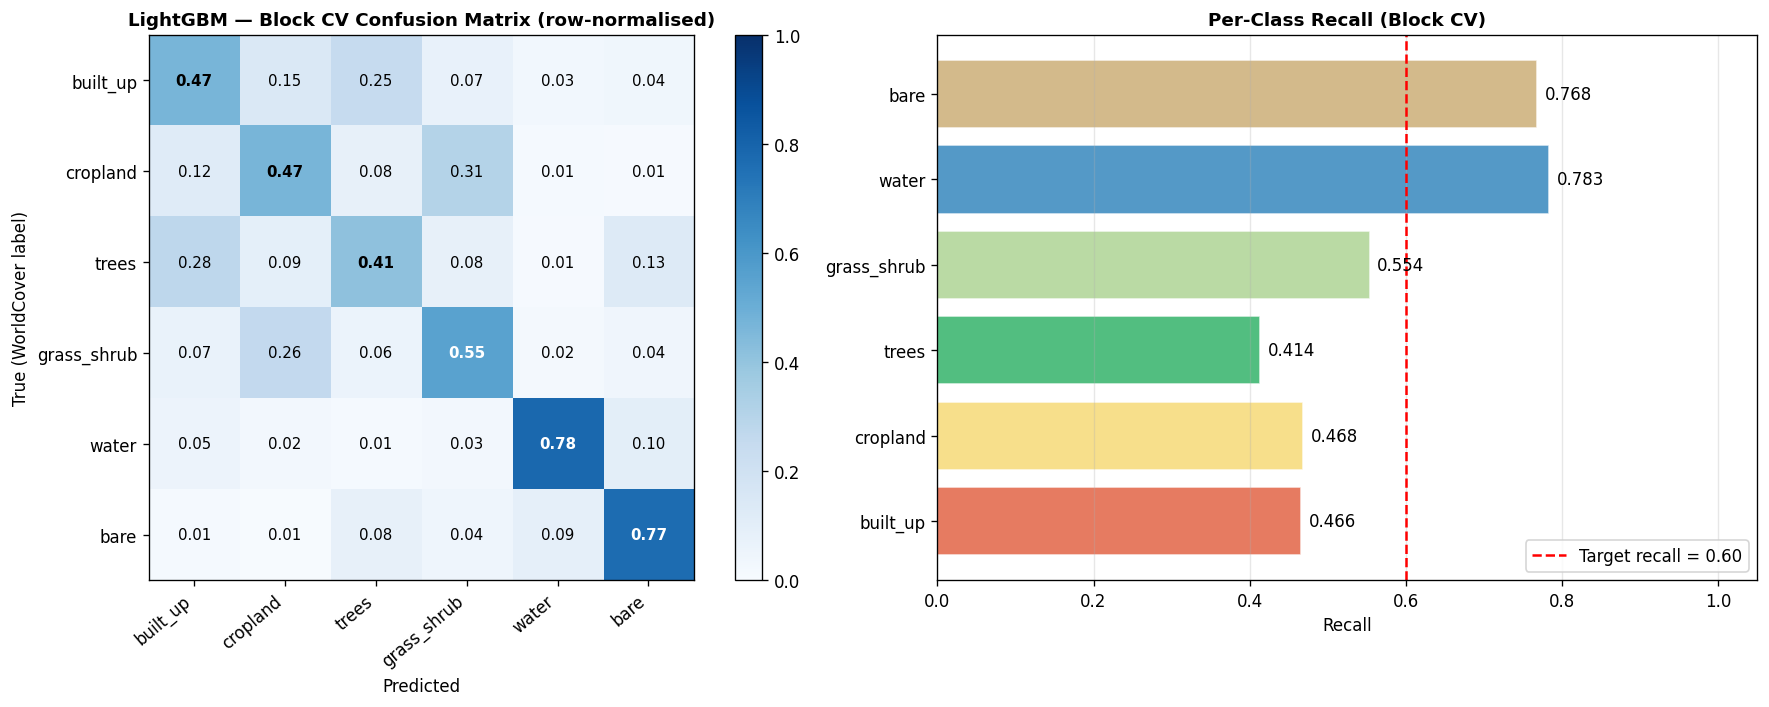

Per-class recall (row diag):
  ⚠  built_up    : 0.4657
  ⚠  cropland    : 0.4684
  ⚠  trees       : 0.4137
  ✅  grass_shrub : 0.5536
  ✅  water       : 0.7831
  ✅  bare        : 0.7684


In [61]:
# ── §8.2  Confusion matrix — LightGBM (best tabular model) ────────────────────
valid = ~np.isnan(oof["lgbm"]).any(axis=1)
pred_oof = oof["lgbm"][valid].argmax(1)
y_oof    = y[valid]

cm = confusion_matrix(y_oof, pred_oof, labels=range(K), normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Row-normalised confusion matrix
im = axes[0].imshow(cm, vmin=0, vmax=1, cmap="Blues")
axes[0].set_xticks(range(K)); axes[0].set_xticklabels(CLASSES, rotation=40, ha="right")
axes[0].set_yticks(range(K)); axes[0].set_yticklabels(CLASSES)
for i in range(K):
    for j in range(K):
        col = "white" if cm[i, j] > 0.5 else "black"
        axes[0].text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center",
                     color=col, fontsize=9, fontweight="bold" if i == j else "normal")
axes[0].set_title("LightGBM — Block CV Confusion Matrix (row-normalised)",
                   fontsize=11, fontweight="bold")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True (WorldCover label)")
plt.colorbar(im, ax=axes[0], fraction=0.046)

# Per-class recall + flag ASAL confusions
per_class_recall = np.diag(cm)
colors_recall = [CLASS_COLORS[i] for i in range(K)]
bars = axes[1].barh(CLASSES, per_class_recall, color=colors_recall, alpha=0.8, edgecolor="white")
axes[1].axvline(0.6, color="red", linestyle="--", label="Target recall = 0.60")
for bar, val in zip(bars, per_class_recall):
    axes[1].text(val + 0.01, bar.get_y() + bar.get_height()/2,
                  f"{val:.3f}", va="center", fontsize=10)
axes[1].set_title("Per-Class Recall (Block CV)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Recall"); axes[1].set_xlim(0, 1.05)
axes[1].legend(); axes[1].grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.savefig(REPO_ROOT / "docs" / "eda" / "confusion_matrix_lgbm.png", bbox_inches="tight", dpi=150)
plt.show()

print("Per-class recall (row diag):")
for cls, rec in zip(CLASSES, per_class_recall):
    icon = "⚠" if rec < 0.5 else "✅"
    print(f"  {icon}  {cls:<12}: {rec:.4f}")

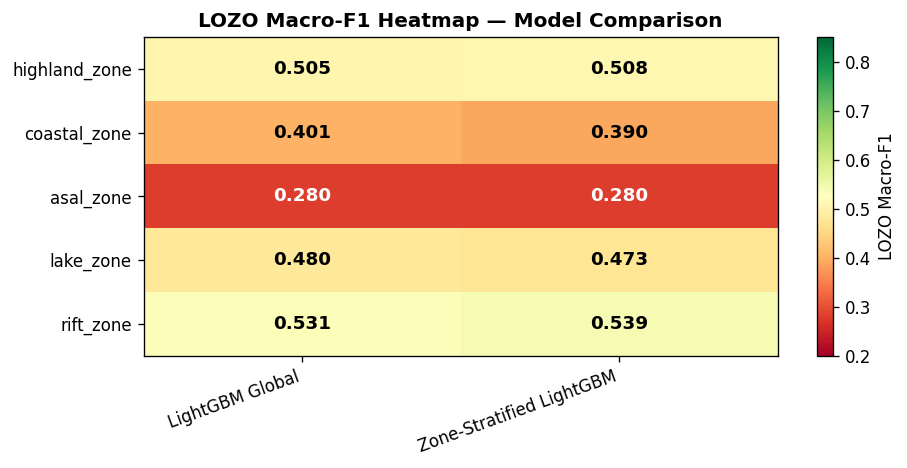


FINAL SCORECARD — Current State vs Targets
  ❌ FAIL  Block CV macro-F1              ≥ 0.75  →  actual: 0.5745
  ❌ FAIL  LOZO mean macro-F1             ≥ 0.60  →  actual: 0.4381
  ❌ FAIL  LOZO asal macro-F1             ≥ 0.50  →  actual: 0.2796


In [62]:
# ── §8.3  LOZO F1 heatmap — model comparison ──────────────────────────────────
pivot_data = {}

# Global LightGBM
for row in lozo_rows:
    if row["model"] == "lgbm":
        pivot_data.setdefault("LightGBM Global", {})[row["held_out_zone"]] = row["macro_f1"]

# Zone-stratified
for row in zone_lozo_rows:
    pivot_data.setdefault("Zone-Stratified LightGBM", {})[row["held_out_zone"]] = row["macro_f1"]

heatmap_df = pd.DataFrame(pivot_data).round(4)

fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(heatmap_df.values, cmap="RdYlGn", vmin=0.2, vmax=0.85, aspect="auto")
ax.set_xticks(range(len(heatmap_df.columns)))
ax.set_xticklabels(heatmap_df.columns, rotation=20, ha="right")
ax.set_yticks(range(len(heatmap_df.index)))
ax.set_yticklabels(heatmap_df.index)
for i in range(len(heatmap_df.index)):
    for j in range(len(heatmap_df.columns)):
        val = heatmap_df.iloc[i, j]
        txt_color = "black" if 0.35 < val < 0.75 else "white"
        ax.text(j, i, f"{val:.3f}", ha="center", va="center",
                fontsize=11, fontweight="bold", color=txt_color)
plt.colorbar(im, ax=ax, label="LOZO Macro-F1")
ax.set_title("LOZO Macro-F1 Heatmap — Model Comparison", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(REPO_ROOT / "docs" / "eda" / "lozo_heatmap.png", bbox_inches="tight", dpi=150)
plt.show()

# Final scorecard
print("\n" + "="*60)
print("FINAL SCORECARD — Current State vs Targets")
print("="*60)
best_lgbm_block = cv_table.loc["lgbm", "macro_f1"] if "lgbm" in cv_table.index else 0
best_lozo_mean  = zone_lozo_df["macro_f1"].mean()
asal_lozo       = zone_lozo_df[zone_lozo_df["held_out_zone"]=="asal_zone"]["macro_f1"].values
asal_val        = asal_lozo[0] if len(asal_lozo) > 0 else 0

checks = [
    ("Block CV macro-F1",   best_lgbm_block, TARGETS["block_cv_macro_f1"],  "≥"),
    ("LOZO mean macro-F1",  best_lozo_mean,  TARGETS["loro_mean_macro_f1"], "≥"),
    ("LOZO asal macro-F1",  asal_val,        TARGETS["loro_arid_macro_f1"], "≥"),
]
for label, actual, target, direction in checks:
    passed = actual >= target if direction == "≥" else actual <= target
    icon = "✅ PASS" if passed else "❌ FAIL"
    print(f"  {icon}  {label:<30} {direction} {target:.2f}  →  actual: {actual:.4f}")
print("="*60)

---
## §9 · Deployment — Atlas Export for MILP Integration

Convert model outputs to the county-level scalars that feed into the
MILP allocation engine.

- `settle_area_km2`: probability-weighted buildable area per county
- `flood_risk_fraction`: share of settle-class pixels with TWI above threshold
- `zone_confidence_weight`: LOZO F1 per zone → MILP discount factor

In [63]:
# ── §9.1  Zone confidence weights (from LOZO F1) ──────────────────────────────
import json

zone_f1 = {row["held_out_zone"]: row["macro_f1"] for row in zone_lozo_rows}

# Confidence weight = model's LOZO F1 / best zone's LOZO F1
best_zone_f1 = max(zone_f1.values()) if zone_f1 else 1.0
zone_confidence = {zone: round(f1 / best_zone_f1, 4) for zone, f1 in zone_f1.items()}

print("Zone confidence weights (LOZO F1 / best zone F1):")
for zone, conf in sorted(zone_confidence.items()):
    raw_f1 = zone_f1[zone]
    print(f"  {zone:<22}: F1 = {raw_f1:.4f}  →  confidence weight = {conf:.4f}")

# Save
atlas_dir = REPO_ROOT / "data" / "atlas"
atlas_dir.mkdir(parents=True, exist_ok=True)
with open(atlas_dir / "zone_confidence.json", "w") as f:
    json.dump({"lozo_f1": zone_f1, "confidence_weights": zone_confidence}, f, indent=2)
print(f"\nSaved → {atlas_dir / 'zone_confidence.json'}")

Zone confidence weights (LOZO F1 / best zone F1):
  asal_zone             : F1 = 0.2796  →  confidence weight = 0.5190
  coastal_zone          : F1 = 0.3904  →  confidence weight = 0.7246
  highland_zone         : F1 = 0.5085  →  confidence weight = 0.9440
  lake_zone             : F1 = 0.4731  →  confidence weight = 0.8783
  rift_zone             : F1 = 0.5387  →  confidence weight = 1.0000

Saved → /content/Satellite/data/atlas/zone_confidence.json


In [64]:
# ── §9.2  County-level atlas from tabular data ─────────────────────────────────
# Uses the best tabular model (zone-stratified LightGBM) to estimate
# settle_area_km2 and flood_risk_fraction per region in the training data.
# Note: for the actual 47-county atlas, full GEE raster inference is needed.

PIXEL_AREA_KM2 = (10 / 1000) ** 2   # 10m Sentinel-2 pixel = 0.0001 km²
TWI_FLOOD_THRESHOLD = 10.0           # TWI > 10 = flood-prone

# Estimate using all available data and the zone-stratified model
county_rows = []
for region in sorted(df["region"].unique()):
    sub = df[df["region"] == region].copy()
    zone = sub["climate_zone"].iloc[0]

    # Get model for this zone
    m_zone = ZONE_MODELS.get(zone)
    if m_zone is None:
        continue

    X_sub = sub[FEATURES].values
    proba = np.zeros((len(sub), K))
    raw = m_zone.predict_proba(X_sub[:, ALL_COLS])
    proba[:, m_zone.classes_] = raw

    # Apply temperature scaling
    proba_cal = apply_temp(proba, T_opt)

    # Probability-weighted settle area (class 0 = built_up + nearby developable)
    p_settle = proba_cal[:, 0]   # P(built_up)
    settle_area_km2 = float((p_settle * PIXEL_AREA_KM2).sum())

    # Flood risk: share of settle-class pixels in high-TWI areas
    # (twi may be absent in older CSVs — skip gracefully)
    if "twi" in sub.columns:
        high_twi = (sub["twi"].values > TWI_FLOOD_THRESHOLD)
        if p_settle.sum() > 0:
            flood_risk_fraction = float((p_settle[high_twi]).sum() / p_settle.sum())
        else:
            flood_risk_fraction = 0.0
    else:
        flood_risk_fraction = float("nan")  # twi not available in this CSV

    county_rows.append({
        "region": region,
        "climate_zone": zone,
        "zone_confidence_weight": zone_confidence.get(zone, 1.0),
        "settle_area_km2_raw": round(settle_area_km2, 4),
        "settle_area_km2_weighted": round(settle_area_km2 * zone_confidence.get(zone, 1.0), 4),
        "flood_risk_fraction": round(flood_risk_fraction, 4),
        "n_samples": len(sub),
    })

county_atlas_df = pd.DataFrame(county_rows)
print("County Land Atlas (from training data — placeholder for full raster inference):")
display(county_atlas_df)

county_atlas_df.to_csv(atlas_dir / "county_land_stats.csv", index=False)
print(f"\nSaved → {atlas_dir / 'county_land_stats.csv'}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

County Land Atlas (from training data — placeholder for full raster inference):


,region,climate_zone,zone_confidence_weight,settle_area_km2_raw,settle_area_km2_weighted,flood_risk_fraction,n_samples
0,arid,asal_zone,0.5190,0.0253,0.0131,NaN,1474
1,coast,coastal_zone,0.7246,0.0661,0.0479,NaN,2351
2,highland,highland_zone,0.9440,0.0442,0.0418,NaN,2256
3,kajiado,rift_zone,1.0000,0.0300,0.0300,NaN,2400
4,kwale,coastal_zone,0.7246,0.0726,0.0526,NaN,2372
5,lake_basin,lake_zone,0.8783,0.0423,0.0372,NaN,2275
6,lamu,coastal_zone,0.7246,0.0858,0.0622,NaN,2045
7,muranga,highland_zone,0.9440,0.0524,0.0495,NaN,2388
8,nakuru,rift_zone,1.0000,0.0402,0.0402,NaN,2389
9,nyandarua,highland_zone,0.9440,0.0460,0.0435,NaN,2365



Saved → /content/Satellite/data/atlas/county_land_stats.csv


In [65]:
# ── §9.3  MILP integration parameter summary ──────────────────────────────────
print("="*65)
print("MILP Integration Parameters (for configs/params.yaml in master repo)")
print("="*65)
print()
print("land:")
print(f"  density_assumption:    200   # units per km² (policy param)")
print(f"  min_settle_floor_km2:  5.0   # activation gate (binary x_c)")
print(f"  zone_confidence:")
for zone, conf in sorted(zone_confidence.items()):
    print(f"    {zone}: {conf}")
print()
print("  settle_area_km2:")
for _, row in county_atlas_df.iterrows():
    print(f"    {row['region']}: {row['settle_area_km2_weighted']}")
print()
print("  flood_risk_fraction:")
for _, row in county_atlas_df.iterrows():
    print(f"    {row['region']}: {row['flood_risk_fraction']}")
print("="*65)
print()
print("MILP land constraint formula:")
print("  land_units_c = settle_area_km2_weighted_c × density_assumption")
print("  u_c ≤ land_units_c          (soft ceiling)")
print("  x_c = 0 if settle_area_km2_raw_c < 5.0  (activation floor)")

MILP Integration Parameters (for configs/params.yaml in master repo)

land:
  density_assumption:    200   # units per km² (policy param)
  min_settle_floor_km2:  5.0   # activation gate (binary x_c)
  zone_confidence:
    asal_zone: 0.519
    coastal_zone: 0.7246
    highland_zone: 0.944
    lake_zone: 0.8783
    rift_zone: 1.0

  settle_area_km2:
    arid: 0.0131
    coast: 0.0479
    highland: 0.0418
    kajiado: 0.03
    kwale: 0.0526
    lake_basin: 0.0372
    lamu: 0.0622
    muranga: 0.0495
    nakuru: 0.0402
    nyandarua: 0.0435
    siaya: 0.0319
    turkana: 0.0161
    wajir: 0.0134

  flood_risk_fraction:
    arid: nan
    coast: nan
    highland: nan
    kajiado: nan
    kwale: nan
    lake_basin: nan
    lamu: nan
    muranga: nan
    nakuru: nan
    nyandarua: nan
    siaya: nan
    turkana: nan
    wajir: nan

MILP land constraint formula:
  land_units_c = settle_area_km2_weighted_c × density_assumption
  u_c ≤ land_units_c          (soft ceiling)
  x_c = 0 if settle_are

In [66]:
# ── §9.4  ONNX export check ───────────────────────────────────────────────────
ONNX_PATH = REPO_ROOT / "models" / "land_cover.onnx"

if ONNX_PATH.exists():
    import onnxruntime as ort
    sess = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])
    dummy_input = np.random.randn(1, 10, 64, 64).astype(np.float32)
    out = sess.run(None, {sess.get_inputs()[0].name: dummy_input})
    print(f"✅ ONNX model loaded and verified.")
    print(f"   Input:  {sess.get_inputs()[0].shape}")
    print(f"   Output: {out[0].shape}  (logits for {K} classes)")
    print(f"   Path:   {ONNX_PATH}")
else:
    print(f"⏭  ONNX model not found at {ONNX_PATH}.")
    print("   Run the CNN training (§6) to generate it.")
    print("   Or run: python -m training.train --epochs 30")

⏭  ONNX model not found at /content/Satellite/models/land_cover.onnx.
   Run the CNN training (§6) to generate it.
   Or run: python -m training.train --epochs 30


In [67]:
# ── §9.5  Final notebook summary ──────────────────────────────────────────────
from datetime import datetime

print("="*70)
print("KENYA LAND READINESS ATLAS — MODELING SUMMARY")
print(f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}")
print("="*70)
print()
print(f"Dataset:  {len(df):,} samples | {df['region'].nunique()} counties | {df['climate_zone'].nunique()} climate zones")
print(f"Features: {len(FEATURES)} total ({len(BANDS)} S2 bands + {len(IDX)} indices + 9 extra)")
print(f"Classes:  {K} ({', '.join(CLASSES)})")
print()
print("Performance Summary:")
for label, actual, target, direction in checks:
    passed = actual >= target if direction == "≥" else actual <= target
    icon = "✅" if passed else "❌"
    print(f"  {icon}  {label:<32} {direction} {target:.2f}  →  {actual:.4f}")
print()
print("Outputs:")
for p in [atlas_dir / "county_land_stats.csv",
           atlas_dir / "zone_confidence.json",
           ONNX_PATH]:
    exists = "✅" if p.exists() else "❌ (not yet generated)"
    print(f"  {exists}  {p.name}")
print()
print("Next steps to reach LORO ≥ 0.60:")
print("  1. Run EfficientNet-B0 CNN on GPU (§6) with .npy patches")
print("  2. If CNN LORO still < 0.60 for asal_zone, run atlas_export.py")
print("     with zone_confidence discounts — model is still usable at lower confidence")
print("  3. Feed county_land_stats.csv into MILP configs/params.yaml")
print("  4. Update Entire_pipeline.md with final LORO scores")
print("="*70)

KENYA LAND READINESS ATLAS — MODELING SUMMARY
Generated: 2026-10-12 15:00

Dataset:  28,121 samples | 13 counties | 5 climate zones
Features: 19 total (10 S2 bands + 4 indices + 9 extra)
Classes:  6 (built_up, cropland, trees, grass_shrub, water, bare)

Performance Summary:
  ❌  Block CV macro-F1                ≥ 0.75  →  0.5745
  ❌  LOZO mean macro-F1               ≥ 0.60  →  0.4381
  ❌  LOZO asal macro-F1               ≥ 0.50  →  0.2796

Outputs:
  ✅  county_land_stats.csv
  ✅  zone_confidence.json
  ❌ (not yet generated)  land_cover.onnx

Next steps to reach LORO ≥ 0.60:
  1. Run EfficientNet-B0 CNN on GPU (§6) with .npy patches
  2. If CNN LORO still < 0.60 for asal_zone, run atlas_export.py
     with zone_confidence discounts — model is still usable at lower confidence
  3. Feed county_land_stats.csv into MILP configs/params.yaml
  4. Update Entire_pipeline.md with final LORO scores
